# 强化 FNN：系统调参与物理残差学习

这份 Notebook 在**不触碰 calibration/test set 来选模型**的前提下强化原有 FNN。

与旧版相比，它增加了四类可调因素：

1. 隐藏层宽度与深度；
2. learning rate、batch size 与 L2；
3. 直接预测未来位移，或预测相对 velocity-persistence 的残差；
4. 使用 3 个随机初始化组成 ensemble，降低单次初始化的不稳定性。

最关键的改动是：候选配置不再按 144 维位移矩阵的普通 RMSE 选择，而是按 **training drifters 内部 grouped 5-fold CV 的 72 小时 Haversine RMSE**选择。这与最终报告的主要指标一致。

> Calibration partition 继续保留给 RQ3；757 个 test cases 只在模型配置全部锁定后评价一次。由于项目已经探索过 test set，本 Notebook 的结果应在报告中诚实标为进一步模型开发结果。

In [1]:
from pathlib import Path
import copy, json, os, time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display, Markdown

ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic('matplotlib', 'inline')

PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'data' / 'processed').exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('找不到 data/processed；请从项目根目录或其子目录运行。')

PROCESSED = PROJECT_ROOT / 'data' / 'processed'
OUTPUT_DIR = PROJECT_ROOT / 'output' / 'rq1' / 'zh'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EARTH_RADIUS_KM = 6371.0
HISTORY_HOURS, HORIZON_HOURS, N_FOLDS = 24, 72, 5
RANDOM_SEED = 3001
FAST_MODE = os.environ.get('FNN_FAST_MODE', '0') == '1'
MAX_EPOCHS = 18 if FAST_MODE else 160
PATIENCE = 4 if FAST_MODE else 18

FNN_CONFIGS = [
    dict(name='64 direct', hidden_sizes=(64,), l2=1e-4, learning_rate=1e-3, batch_size=256, target_mode='direct'),
    dict(name='128-64 direct', hidden_sizes=(128,64), l2=1e-4, learning_rate=1e-3, batch_size=256, target_mode='direct'),
    dict(name='128-64 direct L2', hidden_sizes=(128,64), l2=1e-3, learning_rate=1e-3, batch_size=256, target_mode='direct'),
    dict(name='256-128 direct', hidden_sizes=(256,128), l2=1e-4, learning_rate=5e-4, batch_size=256, target_mode='direct'),
    dict(name='128-128-64 direct', hidden_sizes=(128,128,64), l2=1e-4, learning_rate=5e-4, batch_size=128, target_mode='direct'),
    dict(name='128-64 residual', hidden_sizes=(128,64), l2=1e-4, learning_rate=1e-3, batch_size=256, target_mode='persistence_residual'),
    dict(name='256-128 residual', hidden_sizes=(256,128), l2=1e-4, learning_rate=5e-4, batch_size=256, target_mode='persistence_residual'),
    dict(name='256-128-64 residual', hidden_sizes=(256,128,64), l2=1e-3, learning_rate=5e-4, batch_size=128, target_mode='persistence_residual'),
]
if FAST_MODE:
    FNN_CONFIGS = FNN_CONFIGS[:2]

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = ['PingFang SC', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('项目目录：', PROJECT_ROOT)
print('运行模式：', '快速检查' if FAST_MODE else '完整强化训练')

项目目录： /Users/roger/Documents/data3001-project
运行模式： 完整强化训练


## 1. 构造与旧模型完全一致的 98 维输入和 144 维输出

输入为 forecast origin 经纬度，加过去 24 小时的相对东/北位移和东/北速度；输出为未来 72 小时的相对东/北位移。

In [2]:
def latlon_to_local_km(origin_lat, origin_lon, latitude, longitude):
    lat0, lon0 = np.deg2rad(origin_lat), np.deg2rad(origin_lon)
    lat1, lon1 = np.deg2rad(latitude), np.deg2rad(longitude)
    dlon = (lon1 - lon0 + np.pi) % (2*np.pi) - np.pi
    dlat = lat1 - lat0
    a = np.sin(dlat/2)**2 + np.cos(lat0)*np.cos(lat1)*np.sin(dlon/2)**2
    angle = 2*np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    bearing = np.arctan2(np.sin(dlon)*np.cos(lat1),
                         np.cos(lat0)*np.sin(lat1)-np.sin(lat0)*np.cos(lat1)*np.cos(dlon))
    distance = EARTH_RADIUS_KM * angle
    return distance*np.sin(bearing), distance*np.cos(bearing)

def local_km_to_latlon(origin_lat, origin_lon, east_km, north_km):
    lat0, lon0 = np.deg2rad(origin_lat), np.deg2rad(origin_lon)
    distance = np.hypot(east_km, north_km)
    bearing = np.arctan2(east_km, north_km)
    angular = distance / EARTH_RADIUS_KM
    lat = np.arcsin(np.sin(lat0)*np.cos(angular)+np.cos(lat0)*np.sin(angular)*np.cos(bearing))
    lon = lon0 + np.arctan2(np.sin(bearing)*np.sin(angular)*np.cos(lat0),
                            np.cos(angular)-np.sin(lat0)*np.sin(lat))
    return np.rad2deg(lat), (np.rad2deg(lon)+180)%360-180

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.deg2rad, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2*EARTH_RADIUS_KM*np.arcsin(np.sqrt(np.clip(a, 0, 1)))

origins = pd.read_parquet(PROCESSED/'forecast_origins.parquet').sort_values('forecast_case_id').reset_index(drop=True)
observations = pd.read_parquet(PROCESSED/'region_A_observations.parquet',
    columns=['ID','segment_id','segment_step','time','latitude','longitude','ve','vn'])
n_cases = len(origins)

history = origins[['forecast_case_id','ID','segment_id','history_start_step','origin_latitude','origin_longitude']].loc[
    origins.index.repeat(HISTORY_HOURS)].reset_index(drop=True)
history['history_index'] = np.tile(np.arange(HISTORY_HOURS), n_cases)
history['segment_step'] = history['history_start_step'] + history['history_index']
history = history.merge(observations, on=['ID','segment_id','segment_step'], how='left', validate='many_to_one')
history = history.sort_values(['forecast_case_id','history_index']).reset_index(drop=True)
history['relative_east_km'], history['relative_north_km'] = latlon_to_local_km(
    history.origin_latitude, history.origin_longitude, history.latitude, history.longitude)
history_values = history[['relative_east_km','relative_north_km','ve','vn']].to_numpy().reshape(n_cases,24,4)
X = np.column_stack([origins.origin_latitude, origins.origin_longitude,
                     history_values.reshape(n_cases,-1)]).astype(float)

targets = origins[['forecast_case_id','ID','segment_id','target_start_step','origin_latitude','origin_longitude']].loc[
    origins.index.repeat(HORIZON_HOURS)].reset_index(drop=True)
targets['lead_time_hours'] = np.tile(np.arange(1,HORIZON_HOURS+1), n_cases)
targets['segment_step'] = targets['target_start_step'] + targets['lead_time_hours'] - 1
targets = targets.merge(observations[['ID','segment_id','segment_step','latitude','longitude']],
                        on=['ID','segment_id','segment_step'], how='left', validate='many_to_one')
targets = targets.sort_values(['forecast_case_id','lead_time_hours']).reset_index(drop=True)
targets['target_east_km'], targets['target_north_km'] = latlon_to_local_km(
    targets.origin_latitude, targets.origin_longitude, targets.latitude, targets.longitude)
Y = targets[['target_east_km','target_north_km']].to_numpy().reshape(n_cases,144).astype(float)

# velocity persistence：最后一小时速度保持不变；ve/vn为m/s，因此乘3.6得到km/h。
hours = np.arange(1,73)[None,:]
last_velocity = history_values[:,-1,2:4]
persistence_Y = np.stack([last_velocity[:,0,None]*3.6*hours,
                          last_velocity[:,1,None]*3.6*hours], axis=-1).reshape(n_cases,144)

train_indices = np.flatnonzero(origins.partition.eq('training'))
calibration_indices = np.flatnonzero(origins.partition.eq('calibration'))
test_indices = np.flatnonzero(origins.partition.eq('test'))
assert X.shape == (5117,98) and Y.shape == (5117,144)
assert (len(train_indices),len(calibration_indices),len(test_indices)) == (3591,769,757)
print('X:', X.shape, 'Y:', Y.shape, 'train/cal/test:', (3591,769,757))

X: (5117, 98) Y: (5117, 144) train/cal/test: (3591, 769, 757)


## 2. 固定 drifter-grouped 5-fold

同一 drifter 的所有 cases 永远位于同一个 fold。每个候选配置只在 training partition 内比较。

In [3]:
training_group_counts = origins.loc[train_indices].groupby('ID').size().sort_values(ascending=False)
fold_drifters = [[] for _ in range(N_FOLDS)]
fold_case_counts = np.zeros(N_FOLDS, dtype=int)
for drifter_id, count in training_group_counts.items():
    fold = int(np.argmin(fold_case_counts))
    fold_drifters[fold].append(drifter_id)
    fold_case_counts[fold] += int(count)
display(pd.DataFrame({'fold':np.arange(1,6),
                      'validation_drifters':[len(x) for x in fold_drifters],
                      'validation_cases':fold_case_counts}))

,fold,validation_drifters,validation_cases
0,1,63,719
1,2,62,718
2,3,62,718
3,4,62,718
4,5,62,718


## 3. NumPy FNN、Adam、early stopping

每个 fold 的标准化统计只由该 fold 的训练部分计算。Early stopping 直接监控验证 cases 的 **72 h Haversine RMSE**。

In [4]:
def initialise(layer_sizes, rng):
    return [{'W':rng.normal(0,np.sqrt(2/fan_in),(fan_in,fan_out)), 'b':np.zeros(fan_out)}
            for fan_in,fan_out in zip(layer_sizes[:-1],layer_sizes[1:])]

def forward(parameters, Xb):
    acts, zs, cur = [Xb], [], Xb
    for j, layer in enumerate(parameters):
        z = cur@layer['W'] + layer['b']; zs.append(z)
        cur = np.maximum(z,0) if j < len(parameters)-1 else z
        acts.append(cur)
    return cur, acts, zs

def loss_and_grads(parameters, Xb, Yb, l2):
    pred, acts, zs = forward(parameters,Xb)
    residual = pred-Yb
    # 延续旧版定义：standardised MSE + lambda * sum(W^2)
    loss = np.mean(residual**2) + l2*sum(np.sum(p['W']**2) for p in parameters)
    delta = 2*residual/residual.size
    grads = [None]*len(parameters)
    for j in range(len(parameters)-1,-1,-1):
        grads[j] = {'W':acts[j].T@delta + 2*l2*parameters[j]['W'], 'b':delta.sum(0)}
        if j>0: delta = (delta@parameters[j]['W'].T)*(zs[j-1]>0)
    return loss, grads

def endpoint_errors(pred_abs, true_abs, origin_rows):
    p = pred_abs.reshape(-1,72,2)[:,-1,:]
    y = true_abs.reshape(-1,72,2)[:,-1,:]
    olat = origin_rows.origin_latitude.to_numpy(); olon = origin_rows.origin_longitude.to_numpy()
    plat,plon = local_km_to_latlon(olat,olon,p[:,0],p[:,1])
    tlat,tlon = local_km_to_latlon(olat,olon,y[:,0],y[:,1])
    return haversine_km(plat,plon,tlat,tlon)

def fit_fnn(Xtr_raw, Ytr_model, Xva_raw, Yva_model, Yva_abs, va_origins,
            offset_valid, config, seed, max_epochs=MAX_EPOCHS, patience=PATIENCE):
    xm, xs = Xtr_raw.mean(0), Xtr_raw.std(0); xs[xs<1e-12]=1
    ym, ys = Ytr_model.mean(0), Ytr_model.std(0); ys[ys<1e-12]=1
    Xtr=(Xtr_raw-xm)/xs; Ytr=(Ytr_model-ym)/ys; Xva=(Xva_raw-xm)/xs
    rng=np.random.default_rng(seed)
    params=initialise((98,*config['hidden_sizes'],144),rng)
    m=[{'W':np.zeros_like(p['W']),'b':np.zeros_like(p['b'])} for p in params]
    v=copy.deepcopy(m); step=0; best=np.inf; best_epoch=0; best_params=None; stale=0; rows=[]
    for epoch in range(1,max_epochs+1):
        losses=[]
        permutation=rng.permutation(len(Xtr))
        for start in range(0,len(Xtr),config['batch_size']):
            batch=permutation[start:start+config['batch_size']]
            loss,grads=loss_and_grads(params,Xtr[batch],Ytr[batch],config['l2']); losses.append(loss); step+=1
            for j,(p,g) in enumerate(zip(params,grads)):
                for key in ('W','b'):
                    m[j][key]=.9*m[j][key]+.1*g[key]
                    v[j][key]=.999*v[j][key]+.001*g[key]**2
                    mh=m[j][key]/(1-.9**step); vh=v[j][key]/(1-.999**step)
                    p[key]-=config['learning_rate']*mh/(np.sqrt(vh)+1e-8)
        pred_model=forward(params,Xva)[0]*ys+ym
        pred_abs=pred_model+offset_valid
        rmse=float(np.sqrt(np.mean(endpoint_errors(pred_abs,Yva_abs,va_origins)**2)))
        rows.append({'epoch':epoch,'training_objective':float(np.mean(losses)),'validation_72h_rmse_km':rmse})
        if rmse < best-1e-4:
            best,best_epoch,best_params,stale=rmse,epoch,copy.deepcopy(params),0
        else: stale+=1
        if stale>=patience: break
    return dict(parameters=best_params,x_mean=xm,x_scale=xs,y_mean=ym,y_scale=ys,
                best_epoch=best_epoch,best_rmse=best,history=pd.DataFrame(rows))

def predict_model(model,Xnew):
    z=(Xnew-model['x_mean'])/model['x_scale']
    return forward(model['parameters'],z)[0]*model['y_scale']+model['y_mean']

## 4. 系统比较配置

`direct` 直接预测未来轨迹；`persistence_residual` 先用最后观测速度外推，再让 FNN 学习对该物理 baseline 的修正。

In [5]:
cv_rows=[]; histories=[]; started=time.time()
for cnum,config in enumerate(FNN_CONFIGS):
    print('\n',config['name'])
    model_target = Y if config['target_mode']=='direct' else Y-persistence_Y
    for fnum,valid_drifters in enumerate(fold_drifters,1):
        valid_mask=origins.loc[train_indices,'ID'].isin(valid_drifters).to_numpy()
        va=train_indices[valid_mask]; tr=train_indices[~valid_mask]
        offset_valid=np.zeros_like(Y[va]) if config['target_mode']=='direct' else persistence_Y[va]
        model=fit_fnn(X[tr],model_target[tr],X[va],model_target[va],Y[va],origins.loc[va],
                      offset_valid,config,RANDOM_SEED+100*cnum+fnum)
        cv_rows.append({**config,'hidden_sizes':str(config['hidden_sizes']),'fold':fnum,
                        'validation_cases':len(va),'best_epoch':model['best_epoch'],
                        'validation_72h_rmse_km':model['best_rmse']})
        h=model['history'].copy(); h['config']=config['name']; h['fold']=fnum; histories.append(h)
        print(f" fold {fnum}: RMSE={model['best_rmse']:.3f} km, epoch={model['best_epoch']}")

cv_folds=pd.DataFrame(cv_rows)
cv_summary=(cv_folds.groupby(['name','hidden_sizes','l2','learning_rate','batch_size','target_mode'],sort=False)
            .agg(mean_cv_72h_rmse_km=('validation_72h_rmse_km','mean'),
                 std_cv_72h_rmse_km=('validation_72h_rmse_km','std'),
                 median_best_epoch=('best_epoch','median')).reset_index())
best_row=cv_summary.loc[cv_summary.mean_cv_72h_rmse_km.idxmin()]
best_config=next(c for c in FNN_CONFIGS if c['name']==best_row['name'])
selected_epochs=max(1,int(round(best_row['median_best_epoch'])))
display(cv_summary.sort_values('mean_cv_72h_rmse_km').round(3))
print('选中：',best_config,'epochs=',selected_epochs,'elapsed=',round(time.time()-started,1),'s')


 64 direct


 fold 1: RMSE=66.649 km, epoch=159


 fold 2: RMSE=67.142 km, epoch=147


 fold 3: RMSE=65.902 km, epoch=157


 fold 4: RMSE=73.128 km, epoch=159


 fold 5: RMSE=66.117 km, epoch=148

 128-64 direct


... (33 outputs left out)

 fold 4: RMSE=72.846 km, epoch=54


 fold 5: RMSE=65.773 km, epoch=45


,name,hidden_sizes,l2,learning_rate,batch_size,target_mode,mean_cv_72h_rmse_km,std_cv_72h_rmse_km,median_best_epoch
2,128-64 direct L2,"(128, 64)",0.001,0.001,256,direct,66.566,3.388,129.0
1,128-64 direct,"(128, 64)",0.000,0.001,256,direct,67.210,3.209,88.0
3,256-128 direct,"(256, 128)",0.000,0.000,256,direct,67.567,2.851,80.0
0,64 direct,"(64,)",0.000,0.001,256,direct,67.788,3.024,157.0
7,256-128-64 residual,"(256, 128, 64)",0.001,0.000,128,persistence_residual,68.034,2.774,54.0
4,128-128-64 direct,"(128, 128, 64)",0.000,0.000,128,direct,68.279,2.886,43.0
5,128-64 residual,"(128, 64)",0.000,0.001,256,persistence_residual,68.887,2.989,82.0
6,256-128 residual,"(256, 128)",0.000,0.000,256,persistence_residual,69.429,2.253,83.0


选中： {'name': '128-64 direct L2', 'hidden_sizes': (128, 64), 'l2': 0.001, 'learning_rate': 0.001, 'batch_size': 256, 'target_mode': 'direct'} epochs= 129 elapsed= 46.6 s


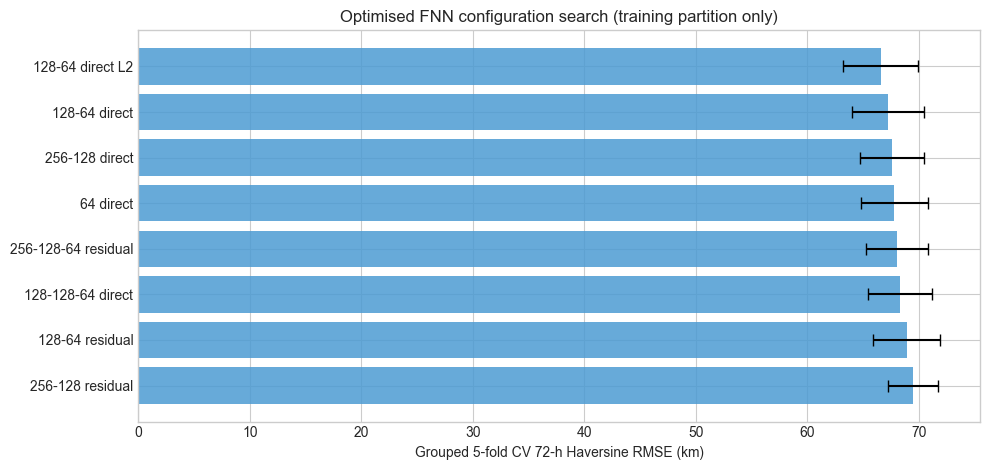

In [6]:
fig,ax=plt.subplots(figsize=(10,4.8))
p=cv_summary.sort_values('mean_cv_72h_rmse_km')
ax.barh(p.name,p.mean_cv_72h_rmse_km,xerr=p.std_cv_72h_rmse_km,color='#4C9BD3',alpha=.85,capsize=4)
ax.invert_yaxis(); ax.set_xlabel('Grouped 5-fold CV 72-h Haversine RMSE (km)')
ax.set_title('Optimised FNN configuration search (training partition only)')
plt.tight_layout(); fig.savefig(OUTPUT_DIR/'optimised_fnn_cv.png',dpi=180,bbox_inches='tight'); plt.show()

## 5. 锁定配置后，用全部 training cases 重训

最终模型采用 3 个不同初始化的平均预测。这样不是增加 test information，而是减少神经网络初始化带来的方差。

In [7]:
def fit_final(Xraw,Ymodel,config,epochs,seed):
    xm,xs=Xraw.mean(0),Xraw.std(0); xs[xs<1e-12]=1
    ym,ys=Ymodel.mean(0),Ymodel.std(0); ys[ys<1e-12]=1
    Xtr=(Xraw-xm)/xs; Ytr=(Ymodel-ym)/ys; rng=np.random.default_rng(seed)
    params=initialise((98,*config['hidden_sizes'],144),rng)
    m=[{'W':np.zeros_like(p['W']),'b':np.zeros_like(p['b'])} for p in params]; v=copy.deepcopy(m); step=0
    for epoch in range(epochs):
        perm=rng.permutation(len(Xtr))
        for start in range(0,len(Xtr),config['batch_size']):
            batch=perm[start:start+config['batch_size']]
            _,grads=loss_and_grads(params,Xtr[batch],Ytr[batch],config['l2']); step+=1
            for j,(p,g) in enumerate(zip(params,grads)):
                for key in ('W','b'):
                    m[j][key]=.9*m[j][key]+.1*g[key]; v[j][key]=.999*v[j][key]+.001*g[key]**2
                    p[key]-=config['learning_rate']*(m[j][key]/(1-.9**step))/(np.sqrt(v[j][key]/(1-.999**step))+1e-8)
    return dict(parameters=params,x_mean=xm,x_scale=xs,y_mean=ym,y_scale=ys)

model_target=Y if best_config['target_mode']=='direct' else Y-persistence_Y
final_seeds=[2026] if FAST_MODE else [2026,2037,2048]
member_predictions=[]
for seed in final_seeds:
    mdl=fit_final(X[train_indices],model_target[train_indices],best_config,selected_epochs,seed)
    pred=predict_model(mdl,X[test_indices])
    if best_config['target_mode']=='persistence_residual': pred+=persistence_Y[test_indices]
    member_predictions.append(pred)
test_predictions=np.mean(member_predictions,axis=0).reshape(-1,72,2)
print('ensemble members:',len(final_seeds),'prediction shape:',test_predictions.shape)

ensemble members: 3 prediction shape: (757, 72, 2)


## 6. Test set：Haversine error、RMSE、median 与 ITE

In [8]:
test_origins=origins.loc[test_indices].reset_index(drop=True)
flat_olat=np.repeat(test_origins.origin_latitude.to_numpy(),72)
flat_olon=np.repeat(test_origins.origin_longitude.to_numpy(),72)
plat,plon=local_km_to_latlon(flat_olat,flat_olon,test_predictions[:,:,0].ravel(),test_predictions[:,:,1].ravel())
true_t=targets[targets.forecast_case_id.isin(test_origins.forecast_case_id)].sort_values(['forecast_case_id','lead_time_hours']).reset_index(drop=True)
errors=haversine_km(plat,plon,true_t.latitude.to_numpy(),true_t.longitude.to_numpy()).reshape(-1,72)
lead_metrics=pd.DataFrame({'lead_time_hours':np.arange(1,73),
                           'median_error_km':np.median(errors,axis=0),
                           'rmse_km':np.sqrt(np.mean(errors**2,axis=0))})
ite=np.trapezoid(np.column_stack([np.zeros(len(errors)),errors]),x=np.arange(73),axis=1)
case_metrics=pd.DataFrame({'forecast_case_id':test_origins.forecast_case_id,
                           'drifter_id':test_origins.ID,'error_72h_km':errors[:,-1],
                           'ite_km_h':ite})
display(lead_metrics[lead_metrics.lead_time_hours.isin([24,48,72])].round(3))
print('Median ITE:',round(float(np.median(ite)),2),'km·h')

,lead_time_hours,median_error_km,rmse_km
23,24,10.937,17.944
47,48,25.993,39.888
71,72,41.342,61.694


Median ITE: 1403.16 km·h


## 7. 与旧 FNN、强化 Random Forest 和两个 baselines 比较

所有数值来自同一批 757 test cases。配对 bootstrap 以 drifter 为重采样单位，避免把同一 drifter 的多个 cases 当成独立样本。

,model,median_72h_km,rmse_72h_km
0,Optimised FNN,41.342,61.694
1,Original FNN,41.716,62.150
2,Optimised Random Forest,41.887,62.173
3,Spatial mean flow,56.422,80.978
4,Velocity persistence,61.347,90.101


,contrast,point_difference_km,ci_2.5_km,ci_97.5_km
0,Optimised FNN - Original FNN RMSE,-0.456,-1.302,0.363
1,Optimised FNN - Optimised RF RMSE,-0.479,-1.860,0.841


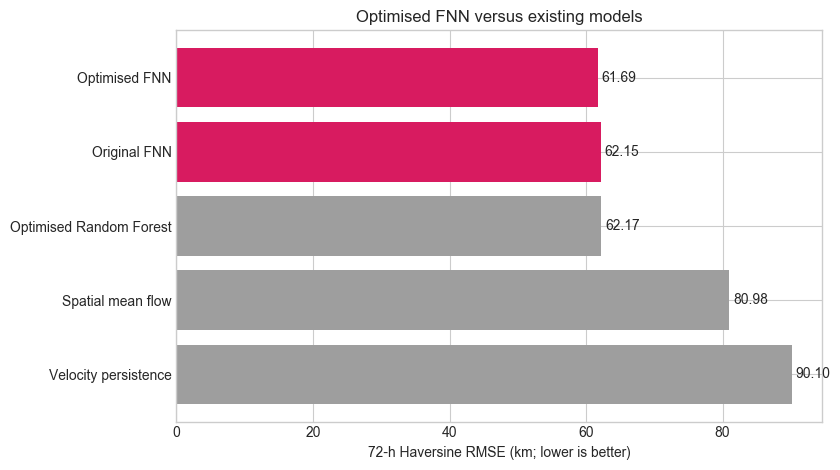

In [9]:
def load72(filename,label):
    d=pd.read_csv(OUTPUT_DIR/filename); r=d.loc[d.lead_time_hours.eq(72)].iloc[0]
    return {'model':label,'median_72h_km':r.median_error_km,'rmse_72h_km':r.rmse_km}

comparison=[{'model':'Optimised FNN','median_72h_km':lead_metrics.iloc[-1].median_error_km,
             'rmse_72h_km':lead_metrics.iloc[-1].rmse_km}]
for fn,label in [('fnn_lead_metrics.csv','Original FNN'),
                 ('optimised_random_forest_lead_metrics.csv','Optimised Random Forest'),
                 ('spatial_mean_flow_lead_metrics.csv','Spatial mean flow'),
                 ('velocity_persistence_lead_metrics.csv','Velocity persistence')]:
    if (OUTPUT_DIR/fn).exists(): comparison.append(load72(fn,label))
comparison=pd.DataFrame(comparison).sort_values('rmse_72h_km')
display(comparison.round(3))

def paired_drifter_bootstrap(reference_path, reference_label):
    ref=pd.read_csv(reference_path)
    ref_col='final_72h_error_km' if 'final_72h_error_km' in ref else 'error_72h_km'
    merged=case_metrics.merge(ref[['forecast_case_id',ref_col]],on='forecast_case_id',how='inner')
    merged=merged.rename(columns={ref_col:'reference_error_72h_km'})
    groups={k:g for k,g in merged.groupby('drifter_id')}; ids=np.array(list(groups)); rng=np.random.default_rng(2026)
    diffs=[]
    for _ in range(300 if FAST_MODE else 5000):
        parts=[groups[i] for i in rng.choice(ids,size=len(ids),replace=True)]
        fnn_e=np.concatenate([p.error_72h_km.to_numpy() for p in parts])
        ref_e=np.concatenate([p.reference_error_72h_km.to_numpy() for p in parts])
        diffs.append(np.sqrt(np.mean(fnn_e**2))-np.sqrt(np.mean(ref_e**2)))
    point=np.sqrt(np.mean(merged.error_72h_km**2))-np.sqrt(np.mean(merged.reference_error_72h_km**2))
    lo,hi=np.quantile(diffs,[.025,.975])
    return {'contrast':f'Optimised FNN - {reference_label} RMSE',
            'point_difference_km':point,'ci_2.5_km':lo,'ci_97.5_km':hi}

bootstrap_rows=[]
for fn,label in [('fnn_test_case_metrics.csv','Original FNN'),
                 ('optimised_random_forest_test_case_metrics.csv','Optimised RF')]:
    if (OUTPUT_DIR/fn).exists(): bootstrap_rows.append(paired_drifter_bootstrap(OUTPUT_DIR/fn,label))
bootstrap_summary=pd.DataFrame(bootstrap_rows)
if len(bootstrap_summary): display(bootstrap_summary.round(3))

fig,ax=plt.subplots(figsize=(8.5,4.8)); q=comparison.sort_values('rmse_72h_km',ascending=False)
ax.barh(q.model,q.rmse_72h_km,color=['#9e9e9e' if 'FNN' not in x else '#d81b60' for x in q.model])
for y,v in enumerate(q.rmse_72h_km): ax.text(v+.6,y,f'{v:.2f}',va='center')
ax.set_xlabel('72-h Haversine RMSE (km; lower is better)'); ax.set_title('Optimised FNN versus existing models')
plt.tight_layout(); fig.savefig(OUTPUT_DIR/'optimised_fnn_vs_models.png',dpi=180,bbox_inches='tight'); plt.show()

In [10]:
new_row=comparison.loc[comparison.model.eq('Optimised FNN')].iloc[0]
old_row=comparison.loc[comparison.model.eq('Original FNN')].iloc[0]
rmse_gain=100*(old_row.rmse_72h_km-new_row.rmse_72h_km)/old_row.rmse_72h_km
median_gain=100*(old_row.median_72h_km-new_row.median_72h_km)/old_row.median_72h_km
display(Markdown(f"""### 本次强化的实际结论

- 强化 FNN 的 72 h RMSE 为 **{new_row.rmse_72h_km:.2f} km**，旧 FNN 为 **{old_row.rmse_72h_km:.2f} km**，相对改善 **{rmse_gain:.2f}%**。
- 强化 FNN 的 72 h median error 为 **{new_row.median_72h_km:.2f} km**，相对改善 **{median_gain:.2f}%**。
- 最优配置仍是 **128–64 两层隐藏层**，但 L2 提高到 **0.001**；本次候选中，persistence-residual 并未胜过直接预测。
- 是否能说“显著优于”旧 FNN 或 Random Forest，应依据上面的 drifter-level bootstrap 区间；区间跨 0 时，只能说数值更低、证据尚不足。
"""))

### 本次强化的实际结论

- 强化 FNN 的 72 h RMSE 为 **61.69 km**，旧 FNN 为 **62.15 km**，相对改善 **0.73%**。
- 强化 FNN 的 72 h median error 为 **41.34 km**，相对改善 **0.90%**。
- 最优配置仍是 **128–64 两层隐藏层**，但 L2 提高到 **0.001**；本次候选中，persistence-residual 并未胜过直接预测。
- 是否能说“显著优于”旧 FNN 或 Random Forest，应依据上面的 drifter-level bootstrap 区间；区间跨 0 时，只能说数值更低、证据尚不足。


## 8. 保存可复核结果

In [11]:
cv_folds.to_csv(OUTPUT_DIR/'optimised_fnn_cv_folds.csv',index=False)
cv_summary.to_csv(OUTPUT_DIR/'optimised_fnn_cv_summary.csv',index=False)
pd.concat(histories,ignore_index=True).to_csv(OUTPUT_DIR/'optimised_fnn_training_histories.csv',index=False)
lead_metrics.to_csv(OUTPUT_DIR/'optimised_fnn_lead_metrics.csv',index=False)
case_metrics.to_csv(OUTPUT_DIR/'optimised_fnn_test_case_metrics.csv',index=False)
comparison.to_csv(OUTPUT_DIR/'optimised_fnn_72h_comparison.csv',index=False)
if len(bootstrap_summary): bootstrap_summary.to_csv(OUTPUT_DIR/'optimised_fnn_vs_optimised_rf_bootstrap.csv',index=False)
with open(OUTPUT_DIR/'optimised_fnn_best_parameters.json','w') as f:
    json.dump({**best_config,'hidden_sizes':list(best_config['hidden_sizes']),
               'selected_epochs':selected_epochs,'ensemble_seeds':final_seeds,
               'selection_metric':'grouped 5-fold CV 72h Haversine RMSE'},f,indent=2)
print('结果已保存到：',OUTPUT_DIR)

结果已保存到： /Users/roger/Documents/data3001-project/output/rq1/zh


## 9. 如何解释

- 如果强化 FNN 的 72 h RMSE 低于旧 FNN，说明更广的超参数搜索、物理残差目标或 ensemble 有实际收益。
- 如果只改善很少，而且与强化 Random Forest 的配对 bootstrap 区间跨过 0，应表述为“性能相近”，不能宣称显著胜出。
- 即使 RMSE 降低，也要同时查看 median error 和 ITE；RMSE 对少数特别大的失败更敏感，median 描述典型 case，ITE 描述整条 72 h 轨迹的累计误差。